In [1]:
import kagglehub

# Download fire dataset from kaggle hub
path = kagglehub.dataset_download("deepcontractor/smoke-detection-dataset")

print("Path to dataset files:", path)

Path to dataset files: /kaggle/input/datasets/deepcontractor/smoke-detection-dataset


In [2]:
import pandas as pd
from matplotlib import pyplot as plt

df = pd.read_csv(filepath_or_buffer="/kaggle/input/datasets/deepcontractor/smoke-detection-dataset/smoke_detection_iot.csv")

In [3]:
df.head()

,Unnamed: 0,UTC,Temperature[C],Humidity[%],TVOC[ppb],eCO2[ppm],Raw H2,Raw Ethanol,Pressure[hPa],PM1.0,PM2.5,NC0.5,NC1.0,NC2.5,CNT,Fire Alarm
0,0,1654733331,20.000,57.36,0,400,12306,18520,939.735,0.0,0.0,0.0,0.0,0.0,0,0
1,1,1654733332,20.015,56.67,0,400,12345,18651,939.744,0.0,0.0,0.0,0.0,0.0,1,0
2,2,1654733333,20.029,55.96,0,400,12374,18764,939.738,0.0,0.0,0.0,0.0,0.0,2,0
3,3,1654733334,20.044,55.28,0,400,12390,18849,939.736,0.0,0.0,0.0,0.0,0.0,3,0
4,4,1654733335,20.059,54.69,0,400,12403,18921,939.744,0.0,0.0,0.0,0.0,0.0,4,0


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 62630 entries, 0 to 62629
Data columns (total 16 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Unnamed: 0      62630 non-null  int64  
 1   UTC             62630 non-null  int64  
 2   Temperature[C]  62630 non-null  float64
 3   Humidity[%]     62630 non-null  float64
 4   TVOC[ppb]       62630 non-null  int64  
 5   eCO2[ppm]       62630 non-null  int64  
 6   Raw H2          62630 non-null  int64  
 7   Raw Ethanol     62630 non-null  int64  
 8   Pressure[hPa]   62630 non-null  float64
 9   PM1.0           62630 non-null  float64
 10  PM2.5           62630 non-null  float64
 11  NC0.5           62630 non-null  float64
 12  NC1.0           62630 non-null  float64
 13  NC2.5           62630 non-null  float64
 14  CNT             62630 non-null  int64  
 15  Fire Alarm      62630 non-null  int64  
dtypes: float64(8), int64(8)
memory usage: 7.6 MB


In [5]:
# drop unnecessary features (Unnamed: identifier, UTC: Coordinated Universal Time, CNT: sample counter )
df = df.drop(["Unnamed: 0", "UTC", "CNT"], axis=1)

In [6]:

df.isnull().sum()

Temperature[C]    0
Humidity[%]       0
TVOC[ppb]         0
eCO2[ppm]         0
Raw H2            0
Raw Ethanol       0
Pressure[hPa]     0
PM1.0             0
PM2.5             0
NC0.5             0
NC1.0             0
NC2.5             0
Fire Alarm        0
dtype: int64

<Axes: >

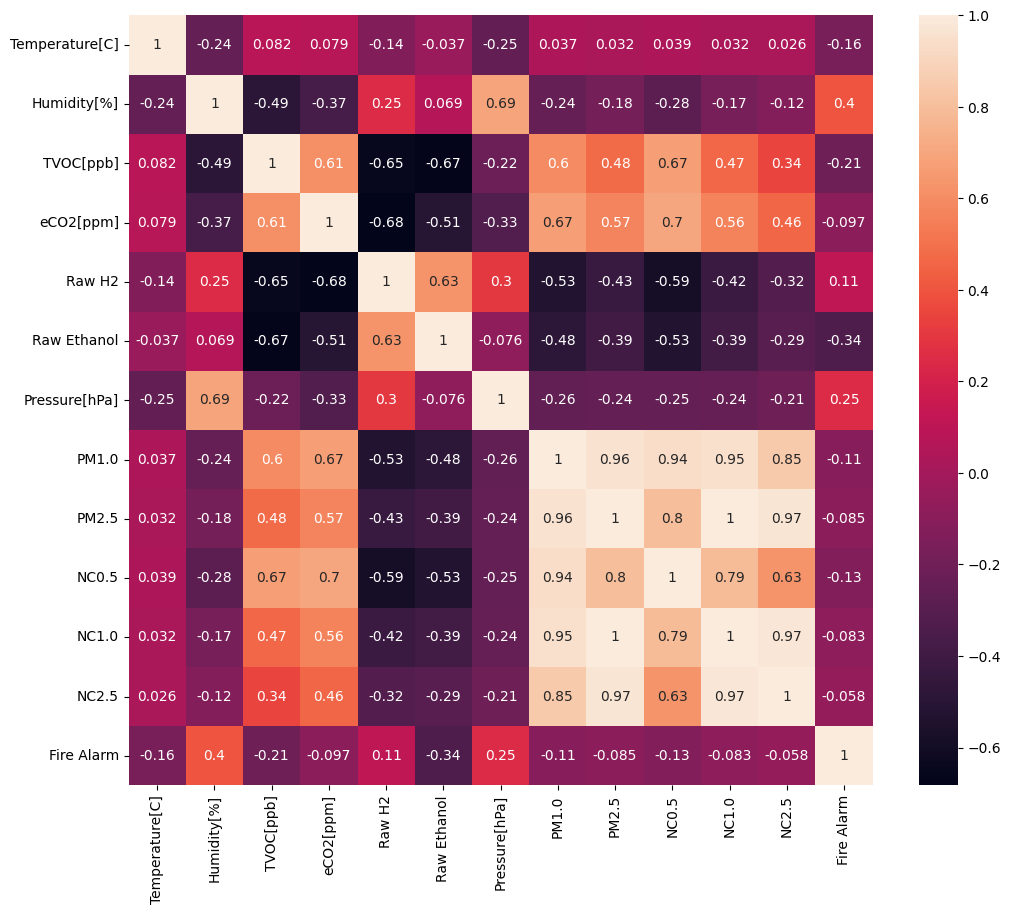

In [7]:
import seaborn as sns
corr = df.corr()
plt.figure(figsize=(12, 10))
sns.heatmap(data=corr,annot=True)

In [8]:
df.describe()

,Temperature[C],Humidity[%],TVOC[ppb],eCO2[ppm],Raw H2,Raw Ethanol,Pressure[hPa],PM1.0,PM2.5,NC0.5,NC1.0,NC2.5,Fire Alarm
count,62630.000000,62630.000000,62630.000000,62630.000000,62630.000000,62630.000000,62630.000000,62630.000000,62630.000000,62630.000000,62630.000000,62630.000000,62630.000000
mean,15.970424,48.539499,1942.057528,670.021044,12942.453936,19754.257912,938.627649,100.594309,184.467770,491.463608,203.586487,80.049042,0.714626
std,14.359576,8.865367,7811.589055,1905.885439,272.464305,609.513156,1.331344,922.524245,1976.305615,4265.661251,2214.738556,1083.383189,0.451596
min,-22.010000,10.740000,0.000000,400.000000,10668.000000,15317.000000,930.852000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,10.994250,47.530000,130.000000,400.000000,12830.000000,19435.000000,938.700000,1.280000,1.340000,8.820000,1.384000,0.033000,0.000000
50%,20.130000,50.150000,981.000000,400.000000,12924.000000,19501.000000,938.816000,1.810000,1.880000,12.450000,1.943000,0.044000,1.000000
75%,25.409500,53.240000,1189.000000,438.000000,13109.000000,20078.000000,939.418000,2.090000,2.180000,14.420000,2.249000,0.051000,1.000000
max,59.930000,75.200000,60000.000000,60000.000000,13803.000000,21410.000000,939.861000,14333.690000,45432.260000,61482.030000,51914.680000,30026.438000,1.000000


In [9]:
# remove duplicated rows if exists
if df.duplicated().sum() >= 1:
  df.drop_duplicates(inplace=True)

df.duplicated().sum()

np.int64(0)

In [10]:
from sklearn.model_selection import train_test_split
y = df["Fire Alarm"]
x = df.drop(["Fire Alarm"], axis=1)
data_train, data_test, train_labels, test_labels  = train_test_split(x, y, test_size=0.2, random_state=42)

In [11]:
# fit the scaling on training data and just make a transform for the test data
# to avoid data leak
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
data_train_scaled = scaler.fit_transform(X=data_train)
data_test_scaled = scaler.transform(X=data_test)

In [12]:
from numpy import mean, std
# checking the "mean" and "standard deviation" after scaling
print("mean", round(mean(data_train_scaled), 4), "\nstd: ",std(data_train_scaled))

mean 0.0 
std:  1.0


In [13]:
# checking the labels distribution
train_labels.value_counts()


Fire Alarm
1    35831
0    14271
Name: count, dtype: int64

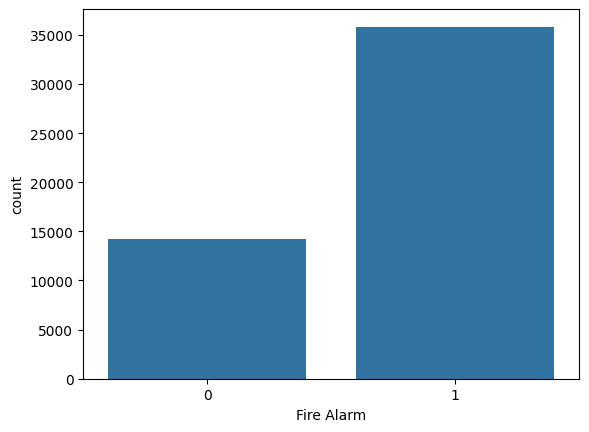

In [14]:
plt.clf()
sns.countplot(x=train_labels)
plt.show()

In [15]:
# We use the SMOTE algorithm to balance our dataset by generating synthetic samples for the minority class
from imblearn.over_sampling import SMOTE
smote = SMOTE(random_state=42)
data_train_resampled, train_labels_resampled = smote.fit_resample(data_train_scaled, train_labels)

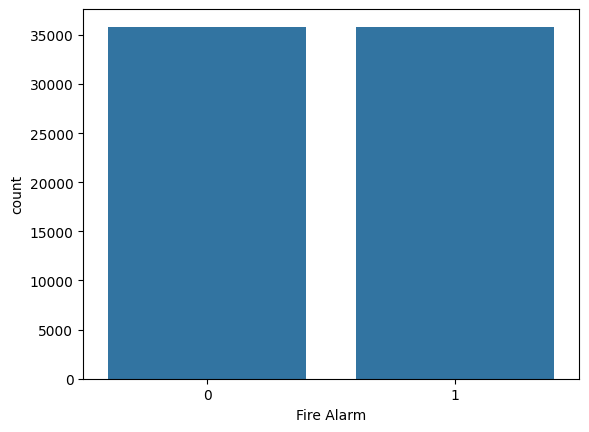

In [16]:
plt.clf()
sns.countplot(x=train_labels_resampled)
plt.show()

In [17]:
data_train_resampled.shape

(71662, 12)

In [18]:
from sklearn.linear_model import LogisticRegression
model = LogisticRegression()
model.fit(data_train_resampled,train_labels_resampled)

LogisticRegression()

In [19]:
from sklearn.metrics import accuracy_score, recall_score, f1_score, precision_score

predicted_labels = model.predict(data_test_scaled)

accuracy = accuracy_score(y_true=test_labels, y_pred=predicted_labels)
recall = recall_score(y_true=test_labels, y_pred=predicted_labels)
f1 = f1_score(y_true=test_labels, y_pred=predicted_labels)
precision = precision_score(y_true=test_labels, y_pred=predicted_labels)

In [20]:
print("accuracy: ",accuracy)
print("recall: ",recall)
print("f1: ",f1)
print("precision: ",precision)

accuracy:  0.907312789398052
recall:  0.9017477033385615
f1:  0.9327307491743438
precision:  0.9659186367454698


In [21]:
from xgboost import XGBClassifier
xgb_model = XGBClassifier()
xgb_model.fit(data_train_resampled,train_labels_resampled)

XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=None, device=None, early_stopping_rounds=None,
              enable_categorical=True, eval_metric=None, feature_types=None,
              feature_weights=None, gamma=None, grow_policy=None,
              importance_type=None, interaction_constraints=None,
              learning_rate=None, max_bin=None, max_cat_threshold=None,
              max_cat_to_onehot=None, max_delta_step=None, max_depth=None,
              max_leaves=None, min_child_weight=None, missing=nan,
              monotone_constraints=None, multi_strategy=None, n_estimators=None,
              n_jobs=None, num_parallel_tree=None, ...)

In [22]:
xgb_predicted_labels = xgb_model.predict(data_test_scaled)

xgb_accuracy = accuracy_score(y_true=test_labels, y_pred=xgb_predicted_labels)
xgb_recall = recall_score(y_true=test_labels, y_pred=xgb_predicted_labels)
xgb_f1 = f1_score(y_true=test_labels, y_pred=xgb_predicted_labels)
xgb_precision = precision_score(y_true=test_labels, y_pred=xgb_predicted_labels)

In [23]:
print("xgb accuracy: ",xgb_accuracy)
print("xgb recall: ",xgb_recall)
print("xgb f1: ",xgb_f1)
print("xgb precision: ",xgb_precision)

xgb accuracy:  1.0
xgb recall:  1.0
xgb f1:  1.0
xgb precision:  1.0


In [24]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report
logistic_regression_cm = confusion_matrix(y_true=test_labels, y_pred=predicted_labels)
logistic_regression_report = classification_report(y_true=test_labels, y_pred=predicted_labels)
print(logistic_regression_report)

              precision    recall  f1-score   support

           0       0.79      0.92      0.85      3600
           1       0.97      0.90      0.93      8926

    accuracy                           0.91     12526
   macro avg       0.88      0.91      0.89     12526
weighted avg       0.92      0.91      0.91     12526



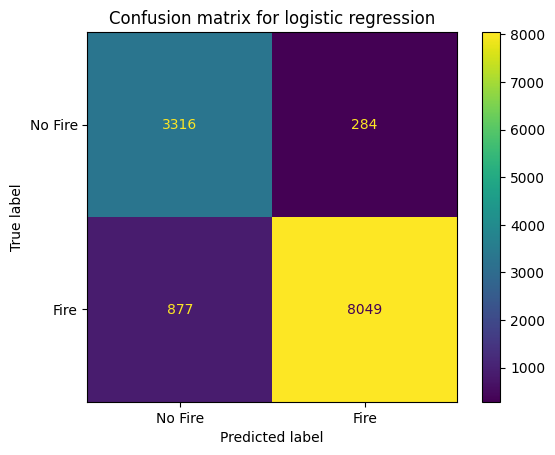

In [25]:

cmd = ConfusionMatrixDisplay(confusion_matrix=logistic_regression_cm, display_labels=['No Fire', 'Fire'])
cmd.plot()
plt.title("Confusion matrix for logistic regression")
plt.show()

In [26]:
xgb_cm = confusion_matrix(y_true=test_labels, y_pred=xgb_predicted_labels)
xgb_report = classification_report(y_true=test_labels, y_pred=xgb_predicted_labels)
print(xgb_report)

              precision    recall  f1-score   support

           0       1.00      1.00      1.00      3600
           1       1.00      1.00      1.00      8926

    accuracy                           1.00     12526
   macro avg       1.00      1.00      1.00     12526
weighted avg       1.00      1.00      1.00     12526



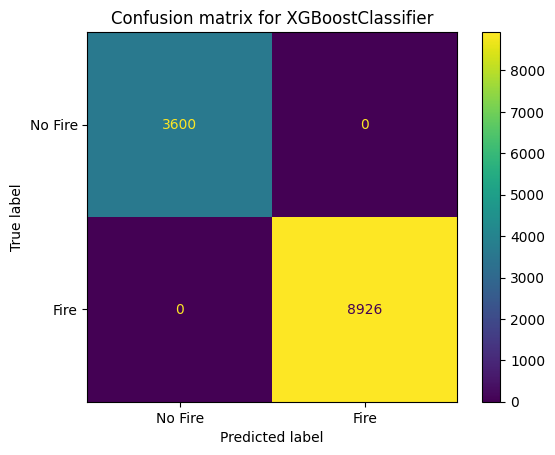

In [27]:
xgb_cmd = ConfusionMatrixDisplay(confusion_matrix=xgb_cm, display_labels=['No Fire', 'Fire'])
xgb_cmd.plot()
plt.title("Confusion matrix for XGBoostClassifier")
plt.show()

In [28]:
import pandas as pd
def get_percentage(value):
  return f'{round(value*100, 3)}%'

# Create a dictionary with the metrics
metrics_data = {
    'Metric': ['Accuracy', 'Precision', 'Recall', 'F1-Score'],
    'LR': [accuracy, precision, recall, f1],
    'XGB_Classifier': [xgb_accuracy, xgb_precision, xgb_recall, xgb_f1]
}

# creating dataframe from dictionary
comparison_df = pd.DataFrame(metrics_data)

# mapping the columns values to be percentage
comparison_df['LR'] = comparison_df['LR'].map(lambda x: get_percentage(x))
comparison_df['XGB_Classifier'] = comparison_df['XGB_Classifier'].map(lambda x: f"{x:.3%}")

# Display the table
display(comparison_df)

,Metric,LR,XGB_Classifier
0,Accuracy,90.731%,100.000%
1,Precision,96.592%,100.000%
2,Recall,90.175%,100.000%
3,F1-Score,93.273%,100.000%


**Which model has a higher Recall score? :** *XGBoostClassifier*

**Why is minimizing False Negatives crucial in fire detection? :** *because a False Negative means that the model predicted there is No Fire but actually there is a Fire, so the model failed to predict the Fire.*

**Interpreting the Recall score of Logistic Regression :** In the Logistic Regression model, we get **Recall = 90.2%**, so we have around **10%** of **False Negative** predictions. This is actually a very dangerous percentage! For example, suppose we have **100 Fires**,out of this total number the model will predict 10 fires as a normal situation (No Fire), and this will cause **high losses**!